# Begin

In [1]:
import os # @launchit.collect
import sys # @launchit.collect
import socket
import copy
from collections import namedtuple, defaultdict, Counter, deque # @launchit.collect
import random
import math
import datetime
import json # @launchit.collect
import pprint # @launchit.collect
import re 
import dataclasses # @launchit.collect
from dataclasses import dataclass # @launchit.collect
import pickle # @launchit.collect
import IPython 
from enum import StrEnum, auto # @launchit.collect
import multiprocessing as mp
import queue

import lark # @launchit.collect

from tqdm.notebook import tqdm

import numpy as np # @launchit.collect
import cupy as cp
import einops
import pandas as pd
import matplotlib.pyplot as plt
import scipy.special

import torch
import torch.nn as nn 
import torch.nn.functional as F
import torchvision.transforms.functional as VF
import torch.optim
import torch.multiprocessing as torch_mp
from torch.distributions import Categorical

import gymnasium as gym
import ale_py
from moviepy.video.io.ImageSequenceClip import ImageSequenceClip
import av

import optuna # @launchit.collect
from optuna.storages import JournalStorage # @launchit.collect
from optuna.storages.journal import JournalFileBackend # @launchit.collect
from optuna.trial import TrialState

project_root_path = '${PROJECT_ROOT_PATH}' # @launchit.collect
build_project_root_path = '${BUILD_PROJECT_ROOT_PATH}' # @launchit.collect
# @launchit.disable
project_root_path = ! git rev-parse --show-toplevel
project_root_path = project_root_path[0]
# @launchit.stop

sys.path.append(os.path.join(project_root_path, 'lib')) # @launchit.collect
sys.path.append(os.path.join(build_project_root_path, 'lib')) # @launchit.collect
import lang_utils as lu # @launchit.collect
import array_utils as au # @launchit.collect
from math_utils import RecursiveAverageFilter, RecursiveMovingAverageFilter
from logging_utils import *
from artifact_registry import * # @launchit.collect
import torch_utils
import launchit 
from hp_utils import * # @launchit.collect
from metrics_collector import RmqSummaryWriter, S3SummaryWriter
from autoincrement import Autoincrement
import command_listener
import ob_preprocessor

# Init

In [2]:
# @launchit.collect
class ExecMode(StrEnum):
    MASTER_NOTEBOOK = auto()
    LAUNCH_NOTEBOOK = auto()
    DOCKER_LAUNCH_NOTEBOOK = auto()
    LAUNCH_MODULE = auto()

In [3]:
def create_config():
    config = namedtuple('Config', 
                        'host_name, ' +
                        'project_root_path, project_root_uri, model_group_uri, subproject_path, data_path, private_data_path, run_path, initrd_path, ' + 
                        'self_fname, self_name, metrics_suite_fname, ' +
                        'subproject_name,' +
                        'is_cuda, cuda_device, docker_registry, exec_mode, is_interactive')(
        host_name=socket.gethostname(),
        project_root_path=project_root_path,
        project_root_uri=f'com.develorium.{os.path.basename(project_root_path)}',
        model_group_uri=None,
        subproject_path=os.path.abspath('.'),
        data_path=os.path.join(project_root_path, 'data'),
        private_data_path=None,
        run_path=None,
        initrd_path=None,
        self_fname=None,
        self_name=None,
        metrics_suite_fname=None,
        subproject_name=None,
        is_cuda=torch.cuda.is_available(),
        cuda_device='cuda' if torch.cuda.is_available() else 'cpu',
        docker_registry='cr.selcloud.ru/neurolab',
        exec_mode=ExecMode.MASTER_NOTEBOOK,
        is_interactive=True,
    )
    
    if IPython.get_ipython() is None:
        module_fname = __file__
        module_basename = os.path.basename(module_fname)
        module_name, _ = os.path.splitext(module_basename)
        
        config = config._replace(self_fname=module_fname, self_name=module_name)
        config = config._replace(exec_mode=ExecMode.LAUNCH_MODULE)
    else:
        with open(IPython.get_ipython().kernel.config['IPKernelApp']['connection_file'], 'r') as cf:
            notebook_fname = json.load(cf).get('jupyter_session')

            if notebook_fname is None:
                notebook_fname = os.path.join(config.subproject_path, os.path.basename('${LAUNCHIT_FNAME}'))
                assert os.path.exists(notebook_fname)
            
            notebook_basename = os.path.basename(notebook_fname)
            notebook_name, notebook_ext = os.path.splitext(notebook_basename)
        
            m = re.match(r'(\w+)-Copy\d+$', notebook_name)
        
            if m: notebook_name = m.group(1) # e.g. Cuml is used to be launched from the copy of the notebook
    
            config = config._replace(self_fname=notebook_fname, self_name=notebook_name)
            
            is_launch = re.match(r'\w+-launch\d+$', notebook_name) is not None

            if is_launch:
                if os.path.exists(os.path.join(project_root_path, '.docker_launch')):
                    config = config._replace(exec_mode=ExecMode.DOCKER_LAUNCH_NOTEBOOK)
                else:
                    config = config._replace(exec_mode=ExecMode.LAUNCH_NOTEBOOK)
            else:
                assert config.exec_mode == ExecMode.MASTER_NOTEBOOK
    
    config = config._replace(is_interactive=config.exec_mode in [ExecMode.MASTER_NOTEBOOK, ExecMode.LAUNCH_NOTEBOOK])
    config = config._replace(subproject_name=os.path.basename(os.path.dirname(config.self_fname)))
    config = config._replace(model_group_uri=f'{config.project_root_uri}.{config.subproject_name}')
    config = config._replace(run_path=os.path.join(project_root_path, 'run', config.subproject_name))
    config = config._replace(initrd_path=os.path.join(project_root_path, 'run', config.subproject_name, 'initrd-' + config.self_name))
    config = config._replace(private_data_path=os.path.join(config.data_path, config.subproject_name))
    config = config._replace(metrics_suite_fname=os.path.join(config.run_path, config.self_name + '.metrics_suite.json'))
    return config

In [4]:
# @launchit.disable_worker
au.init()
LOG = Logging.get()
RNG = np.random.default_rng()
CONFIG = create_config()
LOG.app_name = CONFIG.self_name
LOG.enable('syslog', CONFIG.exec_mode == ExecMode.LAUNCH_MODULE)
LOG.enable('stdout', CONFIG.exec_mode in [ExecMode.MASTER_NOTEBOOK, ExecMode.LAUNCH_NOTEBOOK])
LOG.enable('verbose_stdout', CONFIG.exec_mode == ExecMode.DOCKER_LAUNCH_NOTEBOOK)
LOG(f'CONFIG=\n{pprint.pformat(CONFIG._asdict(), sort_dicts=False)}\n', when=CONFIG.is_interactive)
LOG(f'CONFIG={CONFIG._asdict()}', when=not CONFIG.is_interactive)
os.makedirs(CONFIG.private_data_path, exist_ok=True)
os.makedirs(CONFIG.run_path, exist_ok=True)
os.makedirs(CONFIG.initrd_path, exist_ok=True)

CONFIG=
{'host_name': 'thinkbook',
 'project_root_path': '/home/misha/dev/mine/neurolab',
 'project_root_uri': 'com.develorium.neurolab',
 'model_group_uri': 'com.develorium.neurolab.18_rl',
 'subproject_path': '/home/misha/dev/mine/neurolab/18_rl',
 'data_path': '/home/misha/dev/mine/neurolab/data',
 'private_data_path': '/home/misha/dev/mine/neurolab/data/18_rl',
 'run_path': '/home/misha/dev/mine/neurolab/run/18_rl',
 'initrd_path': '/home/misha/dev/mine/neurolab/run/18_rl/initrd-18n_explore_03',
 'self_fname': '/home/misha/dev/mine/neurolab/18_rl/18n_explore_03.ipynb',
 'self_name': '18n_explore_03',
 'metrics_suite_fname': '/home/misha/dev/mine/neurolab/run/18_rl/18n_explore_03.metrics_suite.json',
 'subproject_name': '18_rl',
 'is_cuda': False,
 'cuda_device': 'cpu',
 'docker_registry': 'cr.selcloud.ru/neurolab',
 'exec_mode': <ExecMode.MASTER_NOTEBOOK: 'master_notebook'>,
 'is_interactive': True}



In [5]:
LaunchComponent = namedtuple('LaunchComponent', 'name version uri main_asset_fname')
    
@dataclass(slots=True)
class Hyperparameters:
    @dataclass(slots=True)
    class Env:
        is_episodic_life: bool = True

    env: Env = dataclasses.field(default_factory=Env)
    
    def launch_component(self):
        name = CONFIG.self_name
        return LaunchComponent(name=name, version=0,  uri=f'{CONFIG.model_group_uri}.{name}', main_asset_fname=CONFIG.self_fname)

HP = Hyperparameters()

In [6]:
ARTIFACT_REGISTRY = ArtifactRegistry(maven_group_id=CONFIG.model_group_uri)

# Agent

In [7]:
LoadAgentResult = namedtuple('LoadAgentResult', 'vision_head, encoder, agent, module, hp, model_name, model_version')

def load_agent(agent_id, artifact_registry, notebook_fname=None):
    coords = hp_parse_artifact_source(agent_id)

    meta = artifact_registry.get_asset_content(coords.model_name, coords.model_version, asset_classifier='meta', asset_ext='json', maven_group_id=coords.group_id)
    meta = json.loads(meta.decode('utf-8'))
    hp = meta['hypers']

    # Vision head
    vision_head_id = hp['vision_head']['parent']['model']
    vision_head_coords = hp_parse_artifact_source(vision_head_id)
    vision_head_notebook_data = artifact_registry.get_asset_content(
        vision_head_coords.model_name, 
        vision_head_coords.model_version, 
        asset_ext='ipynb', 
        maven_group_id=vision_head_coords.group_id,
    )
    vision_head_source_code = launchit.extract_source_code(io.BytesIO(vision_head_notebook_data), collect_inds=[None, 'export'])
    extra_imports = [
        'import ob_preprocessor'
    ]
    vision_head_source_code = '\n'.join(extra_imports) + '\n' + vision_head_source_code 
    vision_head_module = lu.make_module(f'{vision_head_id}_notebook', vision_head_source_code)
    vision_head_module.CONFIG = CONFIG
    vision_head_module.RNG = RNG
    vision_head_module.LOG = LOG
    vision_head_params = artifact_registry.get_asset_content(
        vision_head_coords.model_name, 
        vision_head_coords.model_version, 
        asset_classifier='vision_head_params', 
        asset_ext='json', 
        maven_group_id=coords.group_id,
    )
    vision_head_params = vision_head_module.VisionHead.Params(**json.loads(vision_head_params.decode('utf-8')))
    vision_head = vision_head_module.VisionHead(vision_head_params)

    # Encoder
    encoder_id = hp['encoder']['parent']['model']
    encoder_coords = hp_parse_artifact_source(encoder_id)
    encoder_notebook_data = artifact_registry.get_asset_content(
        encoder_coords.model_name, 
        encoder_coords.model_version, 
        asset_ext='ipynb', 
        maven_group_id=encoder_coords.group_id,
    )
    encoder_source_code = launchit.extract_source_code(io.BytesIO(encoder_notebook_data), collect_inds=[None, 'export'])
    encoder_module = lu.make_module(f'{encoder_id}_notebook', encoder_source_code)
    encoder_module.CONFIG = CONFIG
    encoder_module.RNG = RNG
    encoder_module.LOG = LOG
    encoder_params = artifact_registry.get_asset_content(
        encoder_coords.model_name, 
        encoder_coords.model_version, 
        asset_classifier='encoder_params', 
        asset_ext='json', 
        maven_group_id=coords.group_id,
    )
    encoder_params = encoder_module.Encoder.Params(**json.loads(encoder_params.decode('utf-8')))
    encoder = encoder_module.Encoder(encoder_params)

    # Agent
    if notebook_fname is None:
        notebook_data = artifact_registry.get_asset_content(coords.model_name, coords.model_version, asset_ext='ipynb', maven_group_id=coords.group_id)
        source_code = launchit.extract_source_code(io.BytesIO(notebook_data), collect_inds=[None, 'export'])
    else:
        source_code = launchit.extract_source_code(notebook_fname, collect_inds=[None, 'export'])
        
    # print(source_code)
    # workaround for missing imports
    extra_imports = [
        'from torch.distributions import Categorical',
        'import math',
        'from torch.nn.attention import SDPBackend, sdpa_kernel',
        'import torch_utils',
        'import ob_preprocessor',
    ]
    source_code = '\n'.join(extra_imports) + '\n' + source_code 
    module = lu.make_module(f'{agent_id}_notebook', source_code)
    module.CONFIG = CONFIG
    module.RNG = RNG
    module.LOG = LOG
    module.HP = HP
    agent_params = artifact_registry.get_asset_content(coords.model_name, coords.model_version, asset_classifier='agent_params', asset_ext='json', maven_group_id=coords.group_id)
    agent_params = module.Agent.Params(**json.loads(agent_params.decode('utf-8')))
    agent = module.Agent(agent_params)

    for model_name, model in zip(('vision_head', 'encoder', 'agent'), (vision_head, encoder, agent)):
        pt_data = artifact_registry.get_asset_content(coords.model_name, coords.model_version, asset_classifier=model_name, asset_ext='pt', maven_group_id=coords.group_id)
        
        with io.BytesIO(pt_data) as b:
            kwargs = {}
        
            if not CONFIG.is_cuda:
                kwargs['map_location'] = torch.device('cpu')

            state_dict = torch.load(b, **kwargs)
            model.load_state_dict(state_dict)
            model = model.to(CONFIG.cuda_device)
            model = torch.compile(model, fullgraph=True)
    
    return LoadAgentResult(
        vision_head=vision_head,
        encoder=encoder,
        agent=agent, 
        module=module, 
        hp=hp,
        model_name=coords.model_name,
        model_version=coords.model_version,
    )

In [8]:
# AGENT_ID = '18n_ppo_tr_frostbite_06:117'
# AGENT_ID = '18n_ppo_tr_frostbite_06:172'
# AGENT_ID = '18n_ppo_tr_frostbite_06:124'
# AGENT_ID = '18n_ppo_tr_frostbite_06:162'
# AGENT_ID = '18n_ppo_tr_frostbite_06:232'
# AGENT_ID = '18n_ppo_tr_frostbite_06:277'
# AGENT_ID = '18n_ppo_tr_frostbite_06:304'
# AGENT_ID = '18n_ppo_tr_frostbite_06:326'
# AGENT_ID = '18n_ppo_tr_frostbite_06:335'
# AGENT_ID = '18n_ppo_tr_frostbite_06:524'
# AGENT_ID = '18n_ppo_tr_frostbite_06:529'
# AGENT_ID = '18n_ppo_tr_frostbite_06:559'
# AGENT_ID = '18n_ppo_tr_frostbite_06:610'
# AGENT_ID = '18n_ppo_tr_frostbite_07:296'
# AGENT_ID = '18n_ppo_tr_frostbite_07:321'
# AGENT_ID = '18n_ppo_tr_frostbite_07:340'
# AGENT_ID = '18n_ppo_tr_frostbite_07:722'
# AGENT_ID = '18n_ppo_tr_frostbite_07:673'
# AGENT_ID = '18n_ppo_tr_frostbite_07:171'
# AGENT_ID = '18n_ppo_tr_frostbite_07:269'
# AGENT_ID = '18n_ppo_tr_frostbite_07:257'
# AGENT_ID = '18n_ppo_tr_frostbite_07:247'
# AGENT_ID = '18n_ppo_tr_frostbite_08:120'
# AGENT_ID = '18n_ppo_tr_frostbite_08:63'
# AGENT_ID = '18n_ppo_tr_frostbite_09:456'
# AGENT_ID = '18n_ppo_tr_frostbite_09:573' # champ of 46.3b by episode_lp
# AGENT_ID = '18n_ppo_tr_frostbite_09:505' # champ of 46.1 by levels_passed_mean
# AGENT_ID = '18n_ppo_tr_frostbite_09:394' # skill carrier from 45.3
# AGENT_ID = '18n_ppo_tr_frostbite_07_old:82' # skill carrier from 42.3
# AGENT_ID = '18n_ppo_tr_frostbite_09:598' # champ of 45.3c
# AGENT_ID = '18n_ppo_tr_frostbite_09:736' # skill carrier of 47.3b
AGENT_ID = '18n_ppo_tr_frostbite_09:1021' # champ of 48.5b
lar = load_agent(AGENT_ID, ARTIFACT_REGISTRY)
VISION_HEAD, ENCODER, AGENT, AGENT_MODULE, AGENT_MODEL_NAME, AGENT_MODEL_VERSION = lar.vision_head, lar.encoder, lar.agent, lar.module, lar.model_name, lar.model_version

# Video

## capture_video_of_test_rollout

In [9]:
def capture_video_of_test_rollout(
    vision_head, encoder, agent, agent_module,
    max_steps_count, video_file_name=None, random_seed=None, 
    fps=60, # native ALE FPS=60 
    rams=None, ram_patches=None, 
    capture_preprocessed_obs=False, 
    break_on_level_passed=False, 
    capture_values=False,
    capture_action_plan_logits=False,
    capture_input_sequence=False,
    capture_infos=False,
    is_lossless=False,
):
    preprocess_obs = ob_preprocessor.ObPreprocessor(vision_head.params.ob_shape, cast_to_float=False)
    device = next(iter(agent.parameters())).device
    video_file_name = lu.coalesce(video_file_name, lambda: generate_video_file_name())
    assert video_file_name is not None
    input_sequence = None

    if capture_input_sequence:
        if hasattr(agent.params, 'sequence_ages'):
            input_sequence_inds = (agent.params.sequence_length - 1) - np.array(agent.params.sequence_ages)
            input_sequence_inds = np.sort(input_sequence_inds)
        else:
            input_sequence_inds = range(agent.params.sequence_length)

        if capture_preprocessed_obs:
            assert False, 'not implemented'
        else:
            input_sequence = np.zeros((agent.params.sequence_length, 210, 160, 3), dtype=np.uint8)

    with torch_utils.eval_mode(vision_head), torch_utils.eval_mode(encoder), torch_utils.eval_mode(agent), torch.no_grad():
        captured_frames = []
    
        def append_captured_frame(raw_ob, ob):
            if capture_input_sequence:
                nonlocal input_sequence
                input_sequence[:-1] = input_sequence[1:]
                
                if capture_preprocessed_obs:
                    assert False, 'not implemented'
                else:
                    input_sequence[-1] = raw_ob
                    captured_frame = input_sequence[input_sequence_inds]
                    captured_frame = np.permute_dims(captured_frame, (1, 0, 2, 3)) # e.g. (8, 210, 160, 3) -> (210, 8, 160, 3)
                    captured_frame = captured_frame.reshape(210, -1, 3).copy()
                    captured_frames.append(captured_frame)
            else:
                if capture_preprocessed_obs:
                    assert ob.shape in [(1, 178, 152), (3, 89, 76), (1, 84, 84), (3, 84, 84)], ob.shape
                    captured_frames.append(ob)
                else:
                    captured_frames.append(raw_ob)
        
        values = []
        action_plan_logits = []
        infos = []
        game_meta = defaultdict(int)
        game_meta['random_seed'] = random_seed
        
        env = agent_module.create_envs(1)
        env.reset(seed=random_seed)
        try:
            rams = lu.when(rams is None or len(rams) == 0, {None: None}, rams)
            ram_patches = lu.when(ram_patches is None or len(ram_patches) == 0, [None], ram_patches)
            assert len(rams) > 0
            assert len(ram_patches) > 0
            ram_patcher = agent_module.EnvRamPatcher()
            
            for ram_id, ram in rams.items():
                for ram_patch in ram_patches:
                    story_desc = f'{ram_id}/'
                    story_desc += lu.when(ram_patch, lambda: '+'.join(ram_patch), 'None')
                    LOG(f'Story for video capture="{story_desc}"', when=not CONFIG.is_interactive)
    
                    if ram_patch is not None:
                        ram_patch = ram_patcher(ram_patch)
    
                    assert ram_patch is None or isinstance(ram_patch, dict)
                    
                    reset_options = {}
                    reset_options.update(lu.when(ram is not None, lambda: dict(rams={-1: ram}), {}))
                    reset_options.update(lu.when(ram_patch is not None, lambda: dict(ram_patches={-1: ram_patch}), {}))
                    raw_ob, info = env.reset(options=reset_options)
                    raw_ob = raw_ob[0] # get rid of batch dim
                    ob = torch.tensor(raw_ob).to(device)
                    ob = preprocess_obs(ob)
                    append_captured_frame(raw_ob, ob)
                    features = vision_head(ob)
                    
                    pmask = torch.ones(agent.params.sequence_length).to(device)
                    pmask[-1] = 0
                    ob_latents = torch.zeros(agent.params.sequence_length, agent.params.d_model).to(device)
                    ob_latents[-1] = encoder(features).latents
    
                    if capture_values:
                        values.append([])
    
                    if capture_action_plan_logits:
                        action_plan_logits.append([])

                    if capture_infos:
                        infos.append([info])
    
                    t0 = time.monotonic()
                    
                    for step in range(max_steps_count): 
                        if step > 0 and step % 100 == 0:
                            LOG(f'Captured 100 steps in {time.monotonic() - t0:.3f}s, total steps captured {step}/{max_steps_count}', when=not CONFIG.is_interactive)
                            t0 = time.monotonic()

                        agent_result = agent(
                            ob_latents=ob_latents.unsqueeze(0),
                            padding_masks=pmask.unsqueeze(0),
                        )

                        if capture_values:
                            values[-1].append(agent_result.values[0].item())

                        if capture_action_plan_logits:
                            action_plan_logits[-1].append(agent_result.action_plan_logits[0].cpu().numpy())


                        np_actions = agent_result.actions.cpu().numpy()
                        raw_ob, reward, terminated, truncated, info = env.step(np_actions)
                        
                        if capture_infos:
                            infos[-1].append(info)
                            
                        raw_ob = raw_ob[0] # get rid of batch dim
                        ob = torch.tensor(raw_ob).to(device)
                        ob = preprocess_obs(ob) # e.g. (210,160,3)->(1,84,84) or ...->(3,84,84)
                        append_captured_frame(raw_ob, ob)
                        features = vision_head(ob)
                        
                        pmask = pmask.roll(shifts=-1, dims=0)
                        pmask[-1] = 0
                        ob_latents = ob_latents.roll(shifts=-1, dims=0)
                        ob_latents[-1] = encoder(features).latents
                
                        if HP.env.is_episodic_life and info['is_life_lost'][0]:
                            pmask.fill_(1)
                            pmask[-1] = 0

                            if input_sequence is not None:
                                input_sequence[:-1] = 0
    
                        if info['is_level_passed'][0] and break_on_level_passed:
                            break
    
                        if terminated or truncated:
                            assert info['is_episode_over'][0], info
                            break
                    
                    game_meta['reward'] += info['episode_returns'][0].item()
                    game_meta['frames_count'] += info['episode_lengths'][0].item()
                    game_meta['steps_count'] += step + 1
                    game_meta['levels_passed'] += info['levels_passed'][0].item()
    
            if capture_preprocessed_obs:
                captured_frames = torch.stack(captured_frames, axis=0)
                assert captured_frames.dtype == torch.uint8
    
                if captured_frames.shape[1:] == (1, 178, 152):
                    captured_frames = captured_frames.squeeze(1)
                    assert captured_frames.shape[1:] == (178, 152), captured_frames.shape
                    captured_frames = torch.stack([captured_frames] * 3, axis=-1) # duplicate last channel (N, 178, 152) -> (N, 178, 152, 3)
                    assert captured_frames.shape[1:] == (178, 152, 3), captured_frames.shape
                elif captured_frames.shape[1:] == (1, 84, 84):
                    captured_frames = captured_frames.squeeze(1)
                    assert captured_frames.shape[1:] == (84, 84), captured_frames.shape
                    captured_frames = torch.stack([captured_frames] * 3, axis=-1) # duplicate last channel (N, 84, 84) -> (N, 84, 84, 3)
                    assert captured_frames.shape[1:] == (84, 84, 3), captured_frames.shape
                elif captured_frames.shape[1:] == (3, 84, 84):
                    captured_frames = captured_frames.permute(0, 2, 3, 1)
                    assert captured_frames.shape[1:] == (84, 84, 3), captured_frames.shape
                elif captured_frames.shape[1:] == (3, 89, 76):
                    captured_frames = captured_frames.permute(0, 2, 3, 1)
                    assert captured_frames.shape[1:] == (89, 76, 3), captured_frames.shape
                else:
                    assert False, f'Unsupported {captured_frames.shape=}'
    
                captured_frames = list(captured_frames.cpu().numpy())
            
            clip = ImageSequenceClip(captured_frames, fps=fps / env.frame_skip) 
            try:
                kwargs = {}
    
                if is_lossless:
                    kwargs = dict(codec='libx264', ffmpeg_params=['-crf', '0', '-preset', 'veryslow'])
                
                clip.write_videofile(
                    video_file_name, 
                    logger=None,
                    **kwargs,
                )
            finally:
                clip.close()  # Explicitly closes ffmpeg processes and frees memory
                    
            video_meta = {}
            
            with open(video_file_name, 'rb') as f:
                container = av.open(f)
                video_meta['fps'] = float(container.streams.video[0].average_rate)
                video_stream = container.streams.video[0]
                video_meta['duration'] = float(video_stream.duration * video_stream.time_base)
                video_meta['frame'] = captured_frames[0].shape
    
            d = dict(game=game_meta, video=video_meta)
    
            if capture_values:
                d['values'] = values
    
            if capture_action_plan_logits:
                d['action_plan_logits'] = action_plan_logits

            if capture_infos:
                d['infos'] = infos
    
            return video_file_name, d
        finally:
            del env # nudge Python to release threads and other resources created by EnvVectorizer inside AtariVectorEnv

## Capture

In [20]:
rams = {}
ram_id = None
# ram_id = 'com.develorium.neurolab.frostbite_ram:level5_101:1'
# ram_id = 'com.develorium.neurolab.frostbite_ram:level1_101:1'
# ram_id = 'com.develorium.neurolab.frostbite_ram:level1:1:cls=none'
# ram_id = 'com.develorium.neurolab.frostbite_ram:level2:1:cls=none'
# ram_id = 'com.develorium.neurolab.frostbite_ram:level1:1:cls=exam1'
# ram_id = 'com.develorium.neurolab.frostbite_ram:level1:1:cls=exam2'
# ram_id = 'com.develorium.neurolab.frostbite_ram:level5:1:cls=train5'
# ram_id = 'com.develorium.neurolab.frostbite_ram:level5:1:cls=none'

if ram_id is not None:
    coords = hp_parse_artifact_source(ram_id)
    ram_asset = ARTIFACT_REGISTRY.get_asset_content(
        coords.model_name, 
        coords.model_version, 
        asset_ext='pkl', 
        asset_classifier=coords.asset_classifier, 
        maven_group_id=coords.group_id,
    )
    
    with io.BytesIO(ram_asset) as b:
        ram = pickle.load(b)

    rams[ram_id] = ram
else:
    ram = None
    rams = {}

ram_patches = None
# ram_patches = [
#     ['no_score', 'last_life', 'full_igloo', 'temperature_10', 'bailey_to_the_right_of_igloo', 'bear_to_the_left_of_igloo'],
#     ['no_score', 'last_life', 'full_igloo', 'temperature_10', 'bailey_to_the_left_of_igloo', 'bear_to_the_left_of_igloo'],
#     ['no_score', 'last_life', 'full_igloo', 'temperature_10', 'bear_chases_bailey_to_the_right_of_igloo'],                                        
#     ['no_score', 'last_life', 'full_igloo', 'temperature_10', 'bear_chases_bailey_to_the_left_of_igloo'],
#     ['no_score', 'last_life', 'full_igloo', 'temperature_20', 'bailey_near_center'],
# ]
# ram_patches = [
#     ['no_score', 'three_lives', 'no_igloo'],
# ]
# ram_patches = [
#     ['no_score', 'nine_lives', 'no_igloo'],
# ]
# ram_patches = [
#     ['no_score', 'last_life', 'no_igloo'],
# ]
# ram_patches = [
#     ['nine_lives'],
# ]
# ram_patches = [
#     ['bailey_safe_random_spawn', 'last_life'],
# ]
# ram_patches = [
#     ['last_life'],
# ]
# ram_patches = [
#     ['no_score', 'last_life', 'no_igloo', 'bailey_safe_random_spawn']
# ]
# ram_patches = [
#     ['no_score', 'three_lives', 'no_igloo', 'bailey_safe_random_spawn'],
# ]

VISION_HEAD.eval()
ENCODER.eval()
AGENT.eval()
timestamp = datetime.datetime.now().strftime("%Y.%m.%d-%H:%M:%S")
video_file_name = os.path.join('/home/misha/tmp', f'video-{AGENT_MODEL_NAME}-{AGENT_MODEL_VERSION}-{timestamp}.mp4')

with torch.no_grad():
    capture_result = capture_video_of_test_rollout(
        VISION_HEAD,
        ENCODER,
        AGENT, 
        AGENT_MODULE,
        max_steps_count=10_000, 
        # random_seed=61,
        random_seed=86,
        # random_seed=42 + 32 + 1,
        video_file_name=video_file_name,
        rams=rams,
        ram_patches=ram_patches,
        capture_preprocessed_obs=False,
        break_on_level_passed=False,
        # is_lossless=True,
        # capture_values=True,
        capture_action_plan_logits=True,
        capture_input_sequence=False,
        capture_infos=True,
    )

capture_result[0], capture_result[1]['game']

('/home/misha/tmp/video-18n_ppo_tr_frostbite_09-1021-2026.10.29-23:16:15.mp4',
 defaultdict(int,
             {'random_seed': 86,
              'reward': 9270.0,
              'frames_count': 8803,
              'steps_count': 2194,
              'levels_passed': 4}))

In [11]:
logits = np.vstack(capture_result[1]['action_plan_logits'])
logits = torch.tensor(logits)
print(f'{logits.shape=}')
# torch.round(torch.softmax(logits, dim=-1), decimals=2)[:,0,:]
Categorical(logits=logits).entropy()

logits.shape=torch.Size([2267, 10, 6])


tensor([[0.4475, 0.1071, 0.0691,  ..., 0.2547, 0.9973, 1.3159],
        [0.5349, 0.3850, 0.1547,  ..., 1.1677, 1.2241, 1.2627],
        [0.4790, 0.1738, 0.1384,  ..., 1.0125, 1.1619, 1.2838],
        ...,
        [0.0162, 0.0176, 0.0174,  ..., 0.0255, 0.0320, 0.0329],
        [0.0217, 0.0157, 0.0147,  ..., 0.0201, 0.0237, 0.0256],
        [0.0131, 0.0112, 0.0113,  ..., 0.0151, 0.0168, 0.0181]])

In [12]:
torch.exp(logits[0,0]) / torch.exp(logits[0,0]).sum()

tensor([0.0204, 0.0025, 0.0214, 0.0520, 0.0039, 0.8997])

In [13]:
Categorical(logits=logits[0,0]).entropy()

tensor(0.4475)

In [14]:
torch.exp(logits[0,-1]) / torch.exp(logits[0,-1]).sum()

tensor([0.0552, 0.0122, 0.2701, 0.1881, 0.0193, 0.4551])

In [15]:
Categorical(logits=logits[0,-1]).entropy()

tensor(1.3159)

In [16]:
# probs = torch.tensor([0.02, 0.5, 0.8, 0.2, 0.01, 0])
probs = torch.tensor([1, 1, 1, 1, 1, 1])
probs = probs / probs.sum()
distr = Categorical(probs=probs)
distr.entropy()

tensor(1.7918)

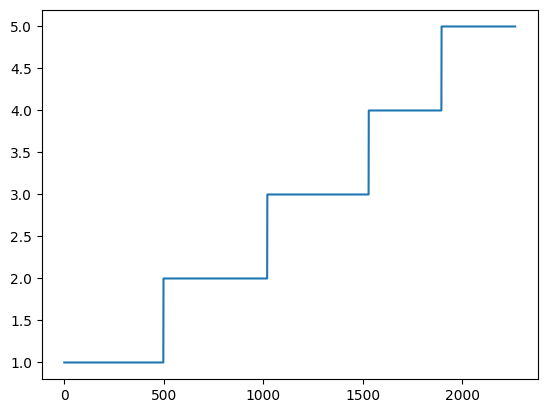

In [17]:
plt.plot(list(map(lambda d: int(d['level'].item()), capture_result[1]['infos'][0])))

# Encoder

## Spatial encoding

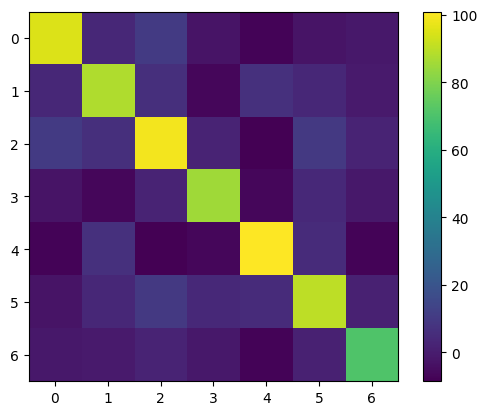

In [18]:
ise = ENCODER.i_spatial_encoding.squeeze(2).squeeze(0)
ise_dp = ise @ ise.T
plt.imshow(ise_dp.detach().numpy())
plt.colorbar();

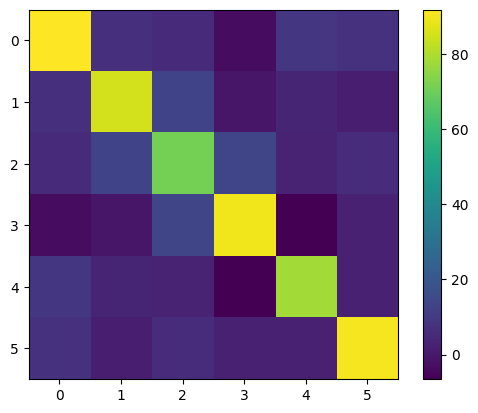

In [19]:
jse = ENCODER.j_spatial_encoding.squeeze(1).squeeze(0)
jse_dp = jse @ jse.T
plt.imshow(jse_dp.detach().numpy())
plt.colorbar();